# Buổi D3: Pipeline và rò rỉ dữ liệu

**Hiện trường.** Một nhóm nghiên cứu báo cáo: *"mô hình đoán đúng 90% trên 100 bệnh nhân, dùng 2000 chỉ số xét nghiệm"*. Chị Hạnh đọc kỹ quy trình và thấy một chi tiết: họ **chọn 20 chỉ số hay nhất trên toàn bộ dữ liệu** rồi mới chia học/thi. Chị nghi điểm 90% là **ảo**.

Chị đúng. Buổi này dạy bạn **tạo ra** lỗi đó trên dữ liệu **hoàn toàn ngẫu nhiên** để thấy nó nguy hiểm thế nào, rồi dùng **pipeline** để ngăn nó từ gốc.

**Rò rỉ dữ liệu** (*data leakage*) là khi thông tin của đề thi lọt vào bước học, dù chỉ gián tiếp. Điểm luôn đẹp hơn thực tế và **không có báo lỗi nào**.

**Mindset của người làm dữ liệu:** điểm đẹp bất thường là một nhân chứng đáng nghi, không phải tin vui.

**Lưu ý:** dữ liệu ngẫu nhiên hoặc mẫu để học, không phải dữ liệu bệnh nhân thật.

## Bản đồ các chặng

| Chặng | Câu hỏi của chặng |
|---|---|
| Chặng 0 | Thấy ngay: 2000 chỉ số ngẫu nhiên mà đoán đúng cao? |
| Chặng 1 | Cách làm đúng: chọn cột chỉ trên phần học |
| Chặng 2 | Pipeline: một chuỗi, mọi bước học lại trong từng vòng |
| Chặng 3 | Rò rỉ thầm lặng khác: chuẩn hóa và điền ô trống trước khi chia |
| Chặng 4 | Cột "gian lận": rò rỉ đáp án qua một cột |
| Chặng 5 | Danh sách kiểm tra chống rò rỉ |

## Chặng 0: Thấy ngay, đoán đúng từ toàn số ngẫu nhiên

**Câu hỏi:** nếu dữ liệu **không có tín hiệu gì**, điểm tối đa nên là bao nhiêu?

Ta dựng bảng **100 bệnh nhân × 2000 chỉ số**, toàn số ngẫu nhiên, nhãn khỏe/bệnh cũng ngẫu nhiên (dựng có chủ đích). Đoán đúng chỉ nên bằng **đoán mò, khoảng 50%**.

Rồi làm theo kiểu "nghiên cứu": chọn 20 chỉ số **tương quan nhất với nhãn trên toàn bộ dữ liệu**, sau đó mới kiểm định chéo.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
BLUE, GRAY = "#1F4E79", "#8C8C8C"
plt.rcParams["figure.figsize"] = (6, 4)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

**Giải thích từng dòng**

- `import numpy as np`: mượn thư viện numpy (máy tính bỏ túi cho cả dãy số), đặt tên ngắn là `np` để gõ cho nhanh.
- `import pandas as pd`: mượn pandas, thư viện làm việc với bảng số liệu giống Excel, tên ngắn là `pd`.
- `import matplotlib.pyplot as plt`: mượn công cụ vẽ biểu đồ, tên ngắn là `plt`.
- `BLUE, GRAY = "#1F4E79", "#8C8C8C"`: gán hai màu dùng suốt bài (xanh đậm và xám). Một dòng gán cùng lúc hai biến, mỗi biến một mã màu.
- `plt.rcParams["figure.figsize"] = (6, 4)`: đặt cỡ hình mặc định: rộng 6, cao 4 (đơn vị inch).
- `plt.rcParams["axes.spines.top"] = False`: bỏ đường viền phía trên khung hình cho gọn mắt.
- `plt.rcParams["axes.spines.right"] = False`: bỏ luôn đường viền bên phải.

In [2]:
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score, StratifiedKFold
rng = np.random.RandomState(0)
X_noise = pd.DataFrame(rng.randn(100, 2000), columns=[f"m{i}" for i in range(2000)])
y_noise = pd.Series(rng.randint(0, 2, 100))
cv = StratifiedKFold(5, shuffle=True, random_state=0)
X_top = SelectKBest(f_classif, k=20).fit_transform(X_noise, y_noise)
wrong = cross_val_score(LogisticRegression(max_iter=1000), X_top, y_noise, cv=cv).mean()
print("X shape:", X_noise.shape, "| labels are pure coin flips")
print("WRONG way (select on all data, then CV):", round(wrong, 3))

X shape: (100, 2000) | labels are pure coin flips
WRONG way (select on all data, then CV): 0.82


**Giải thích từng dòng**

- `rng.randn(100, 2000)`: bảng 100 hàng × 2000 cột số ngẫu nhiên theo phân phối chuẩn.
- `rng.randint(0, 2, 100)`: 100 nhãn 0 hoặc 1 tung đồng xu, **không liên quan** gì đến bảng.
- `SelectKBest(f_classif, k=20)`: bộ chọn cột: chấm mỗi cột theo mức khác biệt giữa hai nhóm (`f_classif`), giữ 20 cột điểm cao nhất.
- `.fit_transform(X_noise, y_noise)`: **học** 20 cột tốt nhất (cần nhãn!) rồi trả bảng chỉ còn 20 cột. Chú ý: bước này đã **nhìn nhãn của mọi ca**.
- `cross_val_score(LogisticRegression(...), X_top, y_noise, cv=cv)`: kiểm định chéo trên bảng đã chọn cột (đã dạy ở D1).

**Cách đọc.**
- **Con số:** điểm kiểu sai là **82,0%**, trong khi sự thật là đoán mò (khoảng 50%).
- **Bức tranh:** trong 2000 cột ngẫu nhiên, thế nào cũng có vài cột **tình cờ** trùng với nhãn. Chọn 20 cột đó **bằng cách nhìn nhãn của cả những ca sẽ làm đề thi**, mô hình đã "thấy trước" đáp án. Dù mọi con số đều là rác, điểm vẫn đẹp.
- **Câu hỏi tiếp:** làm đúng thì điểm ra sao?

**Mang về chặng 0:** chọn cột bằng nhãn **trước khi chia** là rò rỉ, và nó đủ sức biến dữ liệu rác thành điểm cao.

## Chặng 1: Cách làm đúng, chọn cột chỉ trên phần học

**Câu hỏi:** làm sao để việc chọn cột không nhìn trộm đề thi?

Đúng quy trình: **chia trước**, rồi chỉ chọn cột bằng **phần học**, sau đó áp bộ chọn đó (đã học xong) lên phần thi.

In [3]:
from sklearn.model_selection import train_test_split
Xa, Xb, ya, yb = train_test_split(X_noise, y_noise, test_size=0.3, random_state=0, stratify=y_noise)
selector = SelectKBest(f_classif, k=20).fit(Xa, ya)
clf = LogisticRegression(max_iter=1000).fit(selector.transform(Xa), ya)
print("train score:", round(clf.score(selector.transform(Xa), ya), 3))
print("test score (honest):", round(clf.score(selector.transform(Xb), yb), 3))

train score: 1.0
test score (honest): 0.3


**Giải thích từng dòng**

- `train_test_split(...)`: chia trước hết, trước mọi bước nhìn nhãn.
- `SelectKBest(...).fit(Xa, ya)`: chỉ học cột tốt nhất từ phần học (`fit` thôi, chưa biến đổi).
- `selector.transform(Xb)`: áp 20 cột đã chọn lên phần thi. `transform` chỉ **áp dụng** những gì đã học, không nhìn nhãn thi.

**Cách đọc.**
- **Con số:** phần học **100%** (học vẹt, vì 20 cột được chọn để khớp với phần học), phần thi trung thực **30%**.
- **Bức tranh:** đúng như dự đoán: dữ liệu rác thì điểm thi **không vượt mức đoán mò**. Điểm có thể thấp hơn 50% vì tập thi chỉ có 30 ca nên dao động rất mạnh (và vì 20 cột được chọn để khớp với phần học, nên chúng không giúp gì ở phần thi); đừng đọc điểm thấp hơn 50% là "mô hình tệ hơn mò", mà là **không có gì để học**. Quan trọng là bây giờ báo cáo **đúng sự thật**.
- **Câu hỏi tiếp:** nhưng khi dùng kiểm định chéo, phải lặp việc này cho từng vòng. Làm tay rất dễ sai. Cần một công cụ ép đúng quy trình.

**Mang về chặng 1:** mọi bước **học từ dữ liệu** (chọn cột, chuẩn hóa, điền ô trống) phải `fit` trên phần học, rồi `transform` phần thi.

## Chặng 2: Pipeline, một chuỗi mọi bước học lại trong từng vòng

**Câu hỏi:** làm sao tự động hóa quy trình đúng?

Đời thường: dây chuyền nhà máy. Nguyên liệu đi vào đầu dây, qua từng trạm (chọn cột, mô hình), và mỗi lô hàng mới chạy qua dây chuyền **từ đầu**. **Pipeline** đóng gói các bước thành một khối; khi đặt khối đó vào kiểm định chéo, **mỗi vòng học lại tất cả các bước chỉ trên phần học của vòng đó**.

In [4]:
from sklearn.pipeline import make_pipeline
pipe = make_pipeline(SelectKBest(f_classif, k=20), LogisticRegression(max_iter=1000))
right = cross_val_score(pipe, X_noise, y_noise, cv=cv).mean()
print("RIGHT way (selection inside the pipeline):", round(right, 3))
print("steps:", list(pipe.named_steps))

RIGHT way (selection inside the pipeline): 0.42
steps: ['selectkbest', 'logisticregression']


**Giải thích từng dòng**

- `make_pipeline(SelectKBest(...), LogisticRegression(...))`: chuỗi hai trạm: chọn 20 cột, rồi phân loại. (Đã dùng `make_pipeline` từ B4; điều mới là đặt **bước chọn cột** vào trong.)
- `cross_val_score(pipe, X_noise, y_noise, cv=cv)`: truyền **bảng gốc 2000 cột**, không phải bảng đã chọn. Mỗi vòng, pipeline tự chọn cột trên phần học rồi chấm phần thi.
- `pipe.named_steps`: từ điển các bước; tên bước tự đặt theo tên lớp, viết thường.

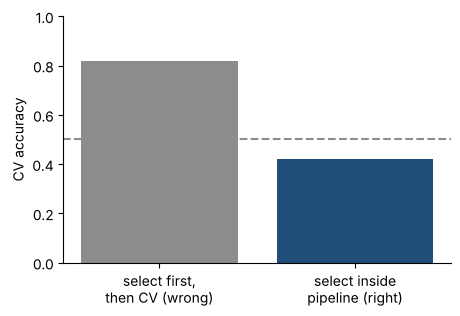

In [5]:
fig, ax = plt.subplots(figsize=(5, 3.2))
ax.bar(["select first,\nthen CV (wrong)", "select inside\npipeline (right)"], [wrong, right], color=[GRAY, BLUE])
ax.axhline(0.5, color=GRAY, linestyle="--"); ax.set_ylim(0, 1); ax.set_ylabel("CV accuracy")
plt.show()

**Giải thích từng dòng**

- `ax.axhline(0.5, ...)`: vạch ngang ở 0,5: mức đoán mò.

**Cách đọc.**
- **Con số:** kiểu sai **82,0%**, kiểu đúng **42,0%** (mức đoán mò 50%; điểm lệch nhẹ khỏi 50% là dao động của 100 ca).
- **Bức tranh:** cùng dữ liệu, cùng mô hình, cùng kiểm định chéo; chỉ khác **vị trí** của bước chọn cột. Pipeline làm cho cách đúng trở thành cách **mặc định, khó làm sai**.
- **Câu hỏi tiếp:** chọn cột rõ ràng là "học từ dữ liệu", còn những bước nghe vô hại hơn như chuẩn hóa thì sao?

**Mang về chặng 2:** đặt mọi bước biến đổi vào trong pipeline, rồi truyền pipeline cho kiểm định chéo.

## Chặng 3: Rò rỉ thầm lặng, chuẩn hóa và điền ô trống trước khi chia

**Câu hỏi:** chuẩn hóa (trừ trung bình, chia độ lệch) trên toàn bộ dữ liệu có gây hại?

Chuẩn hóa dùng **trung bình và độ lệch của cả bảng**, tức nhìn cả phần thi. Ở dữ liệu thông thường, ảnh hưởng thường **nhỏ**; nhưng với dữ liệu ít ca, ngoại lai lớn, hoặc các bước mạnh hơn (như chọn cột), nó có thể lớn. Ta đo thật trên bộ ung thư vú với mô hình k-NN (nhạy với thang đo).

In [6]:
from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import RepeatedStratifiedKFold
Xc, yc = load_breast_cancer(return_X_y=True, as_frame=True)
cv_r = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=0)
leaky = cross_val_score(KNeighborsClassifier(5), StandardScaler().fit_transform(Xc), yc, cv=cv_r)
clean = cross_val_score(make_pipeline(StandardScaler(), KNeighborsClassifier(5)), Xc, yc, cv=cv_r)
print("scale first (leaky):", round(leaky.mean(), 4), "| scale in pipeline (clean):", round(clean.mean(), 4), "| diff:", round(leaky.mean() - clean.mean(), 4))

scale first (leaky): 0.9669 | scale in pipeline (clean): 0.9666 | diff: 0.0004


**Giải thích từng dòng**

- `StandardScaler().fit_transform(Xc)`: chuẩn hóa **cả bảng** một lần, nhìn cả những ca sẽ làm đề thi.
- `RepeatedStratifiedKFold(n_splits=5, n_repeats=10, ...)`: 50 điểm thay vì 5, để so hai cách bớt bị nhiễu.
- `make_pipeline(StandardScaler(), KNeighborsClassifier(5))`: cách đúng: chuẩn hóa học lại trong từng vòng.

**Cách đọc.**
- **Con số:** chênh lệch điểm giữa hai cách là **0,04** điểm phần trăm.
- **Bức tranh:** với chuẩn hóa trên bộ dữ liệu này, chênh lệch rất nhỏ, có khi nằm trong sai số. **Nói thật:** rò rỉ chuẩn hóa không phải lúc nào cũng tệ. Nhưng bạn không biết nó lớn hay nhỏ **cho đến khi đo**, và pipeline cho cách đúng với **không tốn thêm công**. Rò rỉ nguy hiểm nhất là rò rỉ **qua nhãn** (chặng 0) và rò rỉ **qua cột** (chặng 4).
- **Cùng nguyên tắc cho:** điền ô trống bằng trung bình (`SimpleImputer`), mã hóa chữ thành số (`OneHotEncoder`), giảm chiều, cân bằng lớp. Tất cả phải nằm **trong** pipeline.
- **Câu hỏi tiếp:** có kiểu rò rỉ mà pipeline cũng không cứu được không?

**Mang về chặng 3:** rò rỉ qua biến đổi có thể nhỏ hoặc lớn; pipeline loại bỏ câu hỏi đó mà không tốn công.

## Chặng 4: Cột "gian lận", rò rỉ đáp án qua một cột

**Câu hỏi:** nếu trong bảng có một cột mà **chỉ biết sau khi đã biết đáp án** thì sao?

Ví dụ thực tế: dự đoán khách có **hủy dịch vụ** hay không, nhưng bảng có cột *"đã gọi tổng đài hỏi thủ tục hủy"*. Cột này ghi lại **sau** quyết định, không phải trước. Mô hình mê cột đó và điểm lên tới trời, nhưng khi dùng thật (lúc chưa hủy) cột này **chưa có**.

Ta dựng cột như vậy từ bộ ung thư vú: `after_biopsy_code`, một cột chỉ tồn tại **sau** khi đã có kết luận (dựng có chủ đích).

In [7]:
rng = np.random.RandomState(1)
Xl = Xc.copy()
Xl["after_biopsy_code"] = yc * 10 + rng.randn(len(yc))
base = cross_val_score(make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)), Xc, yc, cv=cv).mean()
with_leak = cross_val_score(make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)), Xl, yc, cv=cv).mean()
print("without leaky column:", round(base, 4), "| with leaky column:", round(with_leak, 4))

without leaky column: 0.9789 | with leaky column: 0.9982


**Giải thích từng dòng**

- `Xc.copy()`: sao chép bảng trước khi thêm cột để không làm hỏng bản gốc.
- `Xl['after_biopsy_code'] = yc * 10 + rng.randn(len(yc))`: cột mới gần như bằng đáp án (0 hoặc 10) cộng chút nhiễu. Đây là cột 'biết sau'.

In [8]:
from sklearn.metrics import roc_auc_score
single = {c: roc_auc_score(yc, Xl[c]) for c in Xl.columns}
suspects = pd.Series(single).sub(0.5).abs().add(0.5).sort_values(ascending=False)
print(suspects.head(5).round(3))

after_biopsy_code       1.000
worst perimeter         0.975
worst radius            0.970
worst area              0.970
worst concave points    0.967
dtype: float64


**Giải thích từng dòng**

- `roc_auc_score(yc, Xl[c])`: mỗi **một cột** đứng riêng, nó xếp hạng các ca đúng đến đâu (AUC, đã học ở C2): 0,5 là mò, 1,0 là hoàn hảo.
- `.sub(0.5).abs().add(0.5)`: nếu AUC thấp hơn 0,5 thì cột đảo chiều, lật lại để so sánh cùng thước.
- `sort_values(ascending=False)`: xếp từ cao xuống thấp.

**Cách đọc.**
- **Con số:** bỏ cột gian lận điểm là **97,9%**, thêm vào **99,8%**. Một cột đơn lẻ có AUC **1,000**, trong khi các cột thật cao nhất cũng chỉ cỡ 0,975.
- **Bức tranh:** cột quá giỏi một mình là **báo động đỏ**. Trong thực tế hiếm có chỉ số nào đoán gần hoàn hảo; nếu có, hãy hỏi: *"lúc cần dự đoán thật, cột này đã có chưa?"*
- **Cách phòng:** với mỗi cột, hỏi **thời điểm** nó được ghi lại. Cột ghi sau thời điểm cần dự đoán thì bỏ. Mô hình hay dùng cột nào nhất cũng là chỗ để soi.
- **Lưu ý:** pipeline không cứu được kiểu này, vì cột gian lận hợp lệ về mặt kỹ thuật; lỗi nằm ở **ý nghĩa nghiệp vụ**.

**Mang về chặng 4:** điểm cao bất thường hoặc một cột quá giỏi: kiểm tra xem cột đó có tồn tại tại thời điểm dự đoán thật hay không.

## Chặng 5: Danh sách kiểm tra chống rò rỉ

Trước khi tin một con số điểm, tự hỏi:

1. Mọi bước **học từ dữ liệu** (chọn cột, chuẩn hóa, điền ô trống, cân bằng lớp, giảm chiều) đã nằm **trong pipeline** và `fit` chỉ trên phần học chưa?
2. Tập thi đã **chia trước** mọi thao tác và chỉ dùng **một lần** chưa?
3. Có **dòng trùng** hoặc **cùng một người** xuất hiện ở cả học và thi không? (xem D6)
4. Có cột nào **ghi sau** thời điểm cần dự đoán không?
5. Có cột nào **một mình** đoán gần hoàn hảo không? Nếu có, nghi ngờ trước, mừng sau.
6. Điểm có **cao bất thường** so với mốc ngu và so với mức mà người trong nghề kỳ vọng không?

## Tổng kết

**Mang về theo từng chặng**

| Chặng | Mang về |
|---|---|
| 0 | Chọn cột bằng nhãn trước khi chia biến dữ liệu rác thành điểm cao. |
| 1 | `fit` chỉ trên phần học, `transform` cho phần thi. |
| 2 | Pipeline trong kiểm định chéo: mọi bước học lại ở từng vòng. |
| 3 | Rò rỉ qua chuẩn hóa có thể nhỏ, nhưng pipeline loại bỏ nó miễn phí. |
| 4 | Cột ghi sau thời điểm dự đoán là rò rỉ về nghiệp vụ; điểm quá đẹp là báo động. |
| 5 | Danh sách sáu câu hỏi trước khi tin một con số điểm. |

**Bảng đối chiếu: đời thường, thuật ngữ, tên trong code**

| Đời thường | Thuật ngữ | Tên trong code |
|---|---|---|
| Nhìn trộm đề thi khi ôn | rò rỉ dữ liệu | `SelectKBest(...).fit(X_all, y_all)` trước khi chia |
| Dây chuyền nhà máy | pipeline | `make_pipeline(...)` |
| Học luật từ bài cũ | fit | `.fit(Xa, ya)` |
| Áp luật đã học lên đề mới | transform | `.transform(Xb)` |
| Chọn 20 cột nổi nhất | chọn cột theo thống kê | `SelectKBest(f_classif, k=20)` |
| Cột chỉ biết sau khi đã có đáp án | cột rò rỉ nhãn | `after_biopsy_code` |
| Cột đoán một mình gần hoàn hảo | dấu hiệu nghi ngờ | `roc_auc_score` từng cột |

**Thử thách tự làm**

1. Ở chặng 0, đổi số cột từ 2000 xuống 50 rồi 10. Điểm kiểu sai thay đổi ra sao? Vì sao càng nhiều cột thì rò rỉ càng nặng?
2. Ở chặng 3, thay k-NN bằng `LogisticRegression`. Chênh lệch leaky và clean có đổi không?
3. Tự dựng một cột rò rỉ nhẹ hơn (nhãn cộng nhiễu rất lớn) rồi xem AUC từng cột. Ở mức nhiễu nào thì bạn không còn nhận ra nó nữa?
4. Viết một danh sách kiểm tra rò rỉ cho dự án của chính bạn (ví dụ dự đoán khách hủy dịch vụ): liệt kê các cột và thời điểm ghi của chúng.

**Checklist năng lực** (tự tick khi làm được)

- [ ] Giải thích rò rỉ dữ liệu bằng một ví dụ đời thường.
- [ ] Tái hiện được rò rỉ qua chọn cột trên dữ liệu ngẫu nhiên.
- [ ] Đặt đúng các bước biến đổi vào pipeline.
- [ ] Nhận ra cột ghi sau thời điểm dự đoán.
- [ ] Dùng danh sách sáu câu hỏi để kiểm tra một quy trình.

## Phần thưởng (Tip pro): Cùng một lỗi, nhiều tên gọi


Nhiều bài báo và blog dùng các tên khác nhau cho cùng một họ lỗi: *train-test contamination* (nhiễm tập thi), *look-ahead bias* (nhìn trước tương lai, hay gặp ở chuỗi thời gian), *target leakage* (rò rỉ đáp án qua một cột). Cách nhận biết chung: điểm kiểm định đẹp nhưng khi triển khai thật thì rơi mạnh. Một thói quen tốt: ngay từ đầu giữ lại một **tập thi cuối** chưa từng chạm; nếu điểm trên đó thấp hơn nhiều so với kiểm định chéo, hãy tìm rò rỉ.